# ☕ The Corner Cup Coffee Chain
## Part B — Data Visualisation & Correlation (Python)

**Course:** Statistics and Predictive Analytics for Decision-Making  |  **Group Work 1**
**Group members:** <br> Fathima Mufliha Kottaparamban,<br> Aaliya Kaunain Mustafa Baig,<br> Shubhangi Dubey, <br>Shruti Chalke, <br>Azra Lokhandwala <br> **Date:** 11/11/2026

---

**Purpose.** Maya Chen wants to understand what drives performance across her 12 Corner Cup shops. In this notebook we load the shop data, create three charts, and measure how strongly the numerical variables are related to each other.

| Section | Task | Output |
|---|---|---|
| **0** | Setup | Libraries, colours, chart style |
| **B1** | Load & explore the data | head(), info(), describe() |
| **B2** | Three visualisations | Histogram, Scatter plot, Box plot |
| **B3** | Correlation matrix | Matrix, heat map, strongest & weakest pairs |
| **–** | Summary | Key findings for Maya |

> **How to run:** upload GW1_CornerCup_Data1.csv with the folder icon, then choose **Runtime → Run all**. Every chart is also saved as a picture in the "figures" folder for the report.

## 0. Setup


In [1]:
# --- Libraries ---------------------------------------------------------------
import os                            # files and folders
import pandas as pd                  # tables (DataFrames)
import numpy as np                   # number calculations
import matplotlib.pyplot as plt      # charts
from scipy.stats import linregress   # simple linear regression (trend lines)

# --- House colours: the same as our Excel charts ---------------------------
URBAN    = '#76923C'   # green = Urban shops
SUBURBAN = '#C0504D'   # red   = Suburban shops
ACCENT   = '#953735'   # dark red (titles, highlights)
NEUTRAL  = '#7F7F7F'   # grey (reference lines)
COLOURS  = {'Urban': URBAN, 'Suburban': SUBURBAN}

# --- One chart style for the whole notebook ---------------------------------
plt.rcParams.update({
    'figure.figsize': (8, 5), 'figure.dpi': 110,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlecolor': ACCENT,
    'axes.labelsize': 11, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3,
})

os.makedirs('figures', exist_ok=True)   # charts are saved here for the report
print('Setup complete ✔')

Setup complete ✔


---
## B1. Load and Explore the Data

We read the CSV file into a pandas **DataFrame** (a table, like an Excel sheet) and check that all 12 shops and all 8 columns loaded correctly.

In [2]:
# Load the shop data into a table called "data"
# (accepts either name the course file may have)
for name in ['GW1_CornerCup_Data.csv', 'GW1_CornerCup_Data1.csv']:
    if os.path.exists(name):
        DATA_FILE = name
        break
else:
    raise FileNotFoundError('Upload GW1_CornerCup_Data.csv (or GW1_CornerCup_Data1.csv) with the folder icon on the left.')

data = pd.read_csv(DATA_FILE)
print(f'Loaded "{DATA_FILE}": {data.shape[0]} shops (rows) x {data.shape[1]} variables (columns)')
data.head()

Loaded "GW1_CornerCup_Data1.csv": 12 shops (rows) x 8 variables (columns)


,Shop_Name,Location_Type,Floor_Size_sqft,Num_Staff,Daily_Customers,Avg_Spend_per_Customer,Monthly_Revenue_000,Customer_Satisfaction_Score
0,Downtown Core,Urban,820,6,312,8.4,78.9,4.1
1,Westside Plaza,Urban,1100,8,278,9.2,77.0,4.3
2,University Ave,Suburban,950,7,195,7.8,45.6,3.9
3,Airport Terminal,Urban,680,5,441,6.9,91.4,3.5
4,Midtown Mall,Urban,1250,9,302,10.5,95.5,4.4


In [3]:
# Column names, data types and missing values
data.info()
print('\nMissing values in the whole table:', data.isna().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Shop_Name                    12 non-null     object 
 1   Location_Type                12 non-null     object 
 2   Floor_Size_sqft              12 non-null     int64  
 3   Num_Staff                    12 non-null     int64  
 4   Daily_Customers              12 non-null     int64  
 5   Avg_Spend_per_Customer       12 non-null     float64
 6   Monthly_Revenue_000          12 non-null     float64
 7   Customer_Satisfaction_Score  12 non-null     float64
dtypes: float64(3), int64(3), object(2)
memory usage: 900.0+ bytes

Missing values in the whole table: 0


In [4]:
# Summary statistics for every numerical variable
# (pandas .std() is the SAMPLE standard deviation, the same as Excel's STDEV.S)
data.describe().round(2)

,Floor_Size_sqft,Num_Staff,Daily_Customers,Avg_Spend_per_Customer,Monthly_Revenue_000,Customer_Satisfaction_Score
count,12.00,12.00,12.00,12.00,12.00,12.00
mean,952.50,6.83,269.08,8.73,71.48,4.03
std,244.51,1.75,88.35,1.33,27.82,0.34
min,640.00,5.00,149.00,6.90,32.30,3.50
25%,750.00,5.00,197.25,7.75,47.62,3.78
50%,915.00,6.50,272.50,8.55,71.05,4.05
75%,1120.00,8.00,310.50,9.50,88.62,4.30
max,1400.00,10.00,441.00,11.20,131.00,4.60


**✅ Check.** The data has **12 rows and 8 columns**, no missing values, two text columns (Shop_Name, Location_Type) and six numerical columns. The means and standard deviations match our Excel results in Part A2 (e.g. Daily_Customers: mean 269.08, SD 88.35), so the file loaded correctly.

---
## B2. Three Required Visualisations

### Chart 1 — Histogram of Monthly Revenue (6 bins)
A histogram shows the **shape** of one numerical variable: where most values sit, and whether the data is symmetric or skewed. We add the mean and median as reference lines.

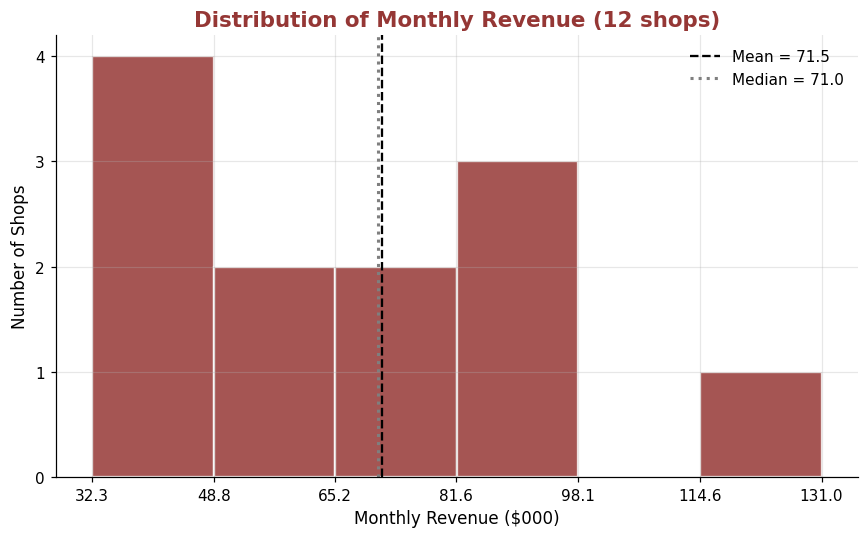

Shops per bin: [4 2 2 3 0 1]
Mean = 71.48 | Median = 71.05 | Skewness = 0.63


In [5]:
rev = data['Monthly_Revenue_000']          # the revenue column

fig, ax = plt.subplots()                   # create an empty chart
counts, edges, _ = ax.hist(rev, bins=6, color=ACCENT, alpha=0.85,
                           edgecolor='white', linewidth=1.5)

# Reference lines for the mean and median
ax.axvline(rev.mean(),   color='black', linestyle='--', linewidth=1.5,
           label=f'Mean = {rev.mean():.1f}')
ax.axvline(rev.median(), color=NEUTRAL, linestyle=':',  linewidth=2,
           label=f'Median = {rev.median():.1f}')

# Titles and labels
ax.set_title('Distribution of Monthly Revenue (12 shops)')
ax.set_xlabel('Monthly Revenue ($000)')
ax.set_ylabel('Number of Shops')
ax.set_xticks(edges.round(1))                             # show the bin edges
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True)) # whole numbers only
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig('figures/B2_chart1_histogram.png', dpi=200, bbox_inches='tight')
plt.show()

print('Shops per bin:', counts.astype(int))
print(f'Mean = {rev.mean():.2f} | Median = {rev.median():.2f} | Skewness = {rev.skew():.2f}')

**Interpretation.** Monthly revenue ranges from about \$32K to \$131K. Most shops sit in the lower and middle bins (\$32K–\$98K), and there is an empty gap before one shop at the far right — Harbour View at \$131K. Because the mean (71.5) and median (71.1) are almost equal, the middle of the distribution is fairly balanced, but the single high-earning shop gives it a slight **right (positive) skew** (skewness ≈ 0.63).

### Chart 2 — Scatter Plot: Daily Customers vs Monthly Revenue
A scatter plot shows the **relationship between two numerical variables**. Each dot is one shop, coloured by location type, with a trend line for all 12 shops.

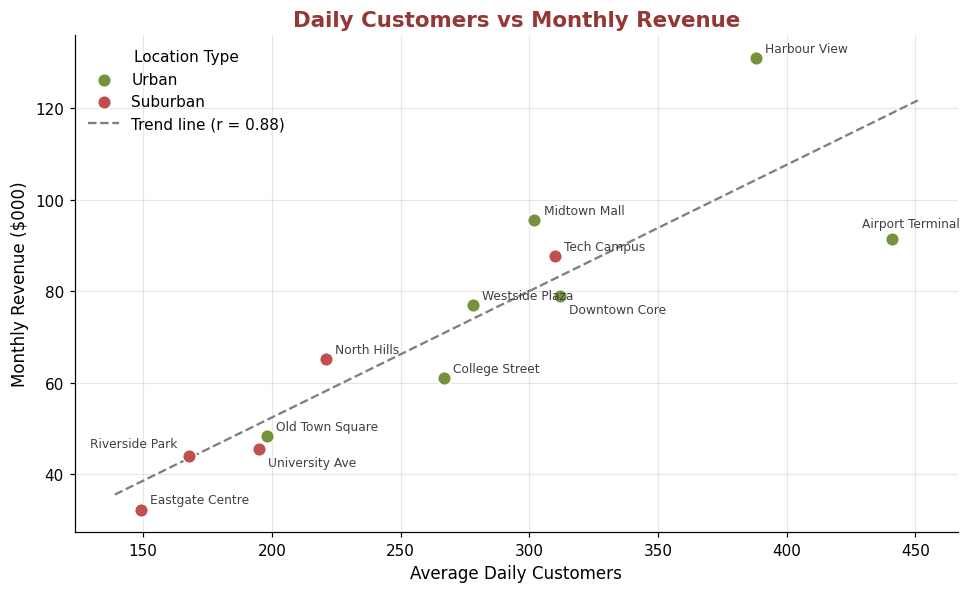

Correlation r = 0.877


In [6]:
x = data['Daily_Customers']                # x-axis: customers per day
y = data['Monthly_Revenue_000']            # y-axis: revenue ($000)
fit = linregress(x, y)                     # trend line through all 12 shops

fig, ax = plt.subplots(figsize=(9, 5.5))

# One set of dots per location type, in our house colours
for loc in ['Urban', 'Suburban']:
    group = data[data['Location_Type'] == loc]
    ax.scatter(group['Daily_Customers'], group['Monthly_Revenue_000'], s=80,
               color=COLOURS[loc], edgecolor='white', linewidth=1, label=loc, zorder=3)

# Trend line
xs = np.linspace(x.min() - 10, x.max() + 10, 100)
ax.plot(xs, fit.intercept + fit.slope * xs, color=NEUTRAL, linestyle='--', linewidth=1.5,
        label=f'Trend line (r = {fit.rvalue:.2f})', zorder=2)

# Label every dot with its shop name (a few labels moved so they don't overlap)
nudge = {'University Ave': (6, -11), 'Riverside Park': (-8, 6),
         'Downtown Core': (6, -11), 'Airport Terminal': (-20, 8)}
for _, shop in data.iterrows():
    ax.annotate(shop['Shop_Name'], (shop['Daily_Customers'], shop['Monthly_Revenue_000']),
                xytext=nudge.get(shop['Shop_Name'], (6, 4)), textcoords='offset points',
                fontsize=8, color='#404040',
                ha='right' if shop['Shop_Name'] == 'Riverside Park' else 'left')

# Titles and labels
ax.set_title('Daily Customers vs Monthly Revenue')
ax.set_xlabel('Average Daily Customers')
ax.set_ylabel('Monthly Revenue ($000)')
ax.legend(title='Location Type', frameon=False, loc='upper left')

plt.tight_layout()
plt.savefig('figures/B2_chart2_scatter.png', dpi=200, bbox_inches='tight')
plt.show()

print(f'Correlation r = {fit.rvalue:.3f}')

**Interpretation.** There is a clear **positive relationship**: shops with more daily customers earn more each month (r = 0.88). The urban (green) shops mostly sit at the upper right with higher traffic and revenue, while the suburban (red) shops cluster at the lower left. Tech Campus is the exception — a suburban shop with high traffic and revenue — which shows that customer traffic, not location type alone, is what drives revenue.

### Chart 3 — Box Plot: Customer Satisfaction, Urban vs Suburban
A box plot compares the **centre and spread** of a variable across groups. The line in the box is the median, the box covers the middle 50% of shops, and the whiskers show the range. Dots show the individual shops.

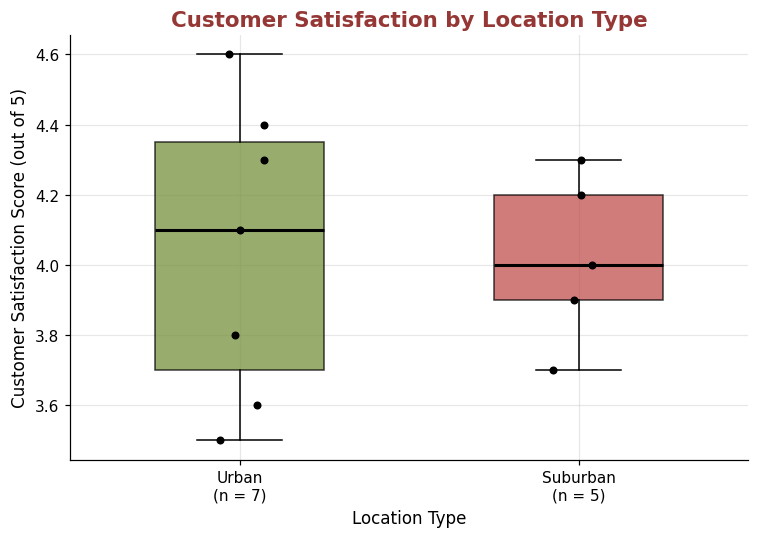

,count,min,25%,50%,75%,max,IQR,Range
Location_Type,,,,,,,,
Urban,7.0,3.5,3.7,4.1,4.35,4.6,0.65,1.1
Suburban,5.0,3.7,3.9,4.0,4.20,4.3,0.30,0.6


In [7]:
groups = ['Urban', 'Suburban']
values = [data.loc[data['Location_Type'] == g, 'Customer_Satisfaction_Score'] for g in groups]

fig, ax = plt.subplots(figsize=(7, 5))
box = ax.boxplot(values, patch_artist=True, widths=0.5,
                 medianprops=dict(color='black', linewidth=2))

# Group names with the number of shops underneath
ax.set_xticks([1, 2], [f'{g}\n(n = {len(v)})' for g, v in zip(groups, values)])

# Colour each box: Urban green, Suburban red
for patch, g in zip(box['boxes'], groups):
    patch.set_facecolor(COLOURS[g])
    patch.set_alpha(0.75)

# Show every shop as a black dot (slightly spread sideways so they don't overlap)
rng = np.random.default_rng(1)
for i, v in enumerate(values, start=1):
    ax.scatter(i + rng.uniform(-0.08, 0.08, len(v)), v, color='black', s=18, zorder=3)

# Titles and labels
ax.set_title('Customer Satisfaction by Location Type')
ax.set_xlabel('Location Type')
ax.set_ylabel('Customer Satisfaction Score (out of 5)')

plt.tight_layout()
plt.savefig('figures/B2_chart3_boxplot.png', dpi=200, bbox_inches='tight')
plt.show()

# Summary table: median, quartiles, IQR and range for each group
summary = data.groupby('Location_Type')['Customer_Satisfaction_Score'].describe()
summary['IQR']   = summary['75%'] - summary['25%']
summary['Range'] = summary['max'] - summary['min']
summary.loc[groups, ['count', 'min', '25%', '50%', '75%', 'max', 'IQR', 'Range']].round(2)

**Interpretation.** Urban shops have a slightly **higher median** satisfaction (4.10 vs 4.00), but they are also **more spread out**: urban scores range from 3.5 to 4.6 (range 1.1, IQR 0.65), while suburban scores stay between 3.7 and 4.3 (range 0.6, IQR 0.30). So suburban shops give a more consistent experience, while the urban group contains both the best-rated shop (Harbour View, 4.6) and the lowest-rated one (Airport Terminal, 3.5).

---
## B3. Correlation Matrix

The **correlation coefficient r** measures how strongly two numerical variables move together, from −1 (perfect negative) through 0 (no linear relationship) to +1 (perfect positive).

In [8]:
# Correlation matrix for the six numerical variables
numeric = data.select_dtypes('number')     # keep only the number columns
corr = numeric.corr()                      # Pearson correlation (r) for every pair
corr.round(3)

,Floor_Size_sqft,Num_Staff,Daily_Customers,Avg_Spend_per_Customer,Monthly_Revenue_000,Customer_Satisfaction_Score
Floor_Size_sqft,1.000,0.985,0.293,0.913,0.675,0.911
Num_Staff,0.985,1.000,0.309,0.930,0.687,0.876
Daily_Customers,0.293,0.309,1.000,0.237,0.877,0.210
Avg_Spend_per_Customer,0.913,0.930,0.237,1.000,0.661,0.888
Monthly_Revenue_000,0.675,0.687,0.877,0.661,1.000,0.600
Customer_Satisfaction_Score,0.911,0.876,0.210,0.888,0.600,1.000


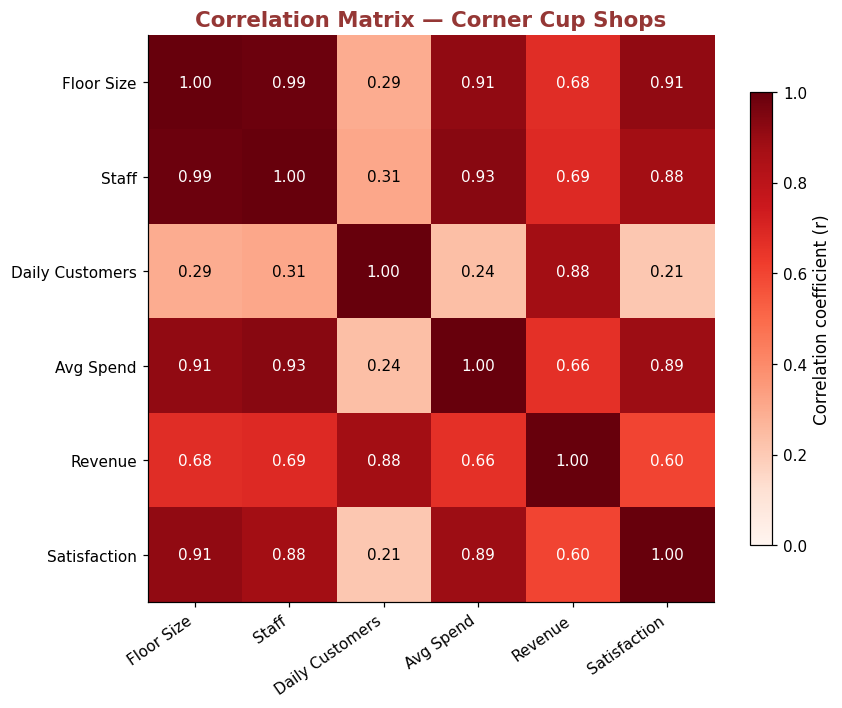

In [9]:
# Heat map: darker red = stronger positive relationship
short = ['Floor Size', 'Staff', 'Daily Customers', 'Avg Spend', 'Revenue', 'Satisfaction']

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap='Reds', vmin=0, vmax=1)
ax.set_xticks(range(6), short, rotation=35, ha='right')
ax.set_yticks(range(6), short)
ax.grid(False)

# Write the r value inside each square
for i in range(6):
    for j in range(6):
        r = corr.iloc[i, j]
        ax.text(j, i, f'{r:.2f}', ha='center', va='center', fontsize=10,
                color='white' if r > 0.6 else 'black')

fig.colorbar(im, ax=ax, shrink=0.8, label='Correlation coefficient (r)')
ax.set_title('Correlation Matrix — Corner Cup Shops')
plt.tight_layout()
plt.savefig('figures/B3_correlation_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

In [10]:
# Rank every pair of variables from strongest to weakest correlation
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))   # keep each pair once
             .stack().dropna().rename('r').reset_index()
             .rename(columns={'level_0': 'Variable 1', 'level_1': 'Variable 2'})
             .sort_values('r', ascending=False, ignore_index=True))
pairs.index += 1                                                      # number from 1

def strength(r):
    r = abs(r)
    return ('Very strong' if r >= 0.9 else 'Strong' if r >= 0.7 else
            'Moderate' if r >= 0.4 else 'Weak' if r >= 0.1 else 'Near zero')
pairs['Strength'] = pairs['r'].apply(strength)

print('▲ Two strongest positive correlations')
display(pairs.head(2).round(3))
print('\n▼ Weakest correlations')
display(pairs.tail(4).round(3))
print('\n● What moves with Monthly Revenue?')
display(corr['Monthly_Revenue_000'].drop('Monthly_Revenue_000')
            .sort_values(ascending=False).round(3).to_frame('r with Revenue'))

▲ Two strongest positive correlations


,Variable 1,Variable 2,r,Strength
1,Floor_Size_sqft,Num_Staff,0.985,Very strong
2,Num_Staff,Avg_Spend_per_Customer,0.930,Very strong



▼ Weakest correlations


,Variable 1,Variable 2,r,Strength
12,Num_Staff,Daily_Customers,0.309,Weak
13,Floor_Size_sqft,Daily_Customers,0.293,Weak
14,Daily_Customers,Avg_Spend_per_Customer,0.237,Weak
15,Daily_Customers,Customer_Satisfaction_Score,0.210,Weak



● What moves with Monthly Revenue?


,r with Revenue
Daily_Customers,0.877
Num_Staff,0.687
Floor_Size_sqft,0.675
Avg_Spend_per_Customer,0.661
Customer_Satisfaction_Score,0.600


**Strongest positive pairs.**
1. **Floor_Size_sqft & Num_Staff: r = 0.985** — bigger shops employ more staff (an almost perfect relationship).
2. **Num_Staff & Avg_Spend_per_Customer: r = 0.930** — shops with more staff also have customers who spend more per visit.

**Weak / near-zero pairs.** **Daily_Customers** has only weak relationships with Satisfaction (r = 0.21), Avg Spend (r = 0.24), Floor Size (r = 0.29) and Staff (r = 0.31). This means a busy shop is not necessarily a big shop, and attracting more customers does not automatically make them happier or make them spend more — customer traffic behaves independently of the shop's size and service.

**What drives monthly revenue?** Daily customers has by far the strongest link with revenue (r = 0.88), so foot traffic is the main revenue driver. Floor size, staff and average spend have only moderate links (r ≈ 0.66–0.69), and satisfaction is the weakest of the group (r = 0.60). Larger shops earn more per customer and keep customers happier, but they do not bring in more customers. For Maya, this suggests that the best way to grow revenue is to choose busy, high-traffic locations — not simply to open bigger shops. *(Correlation shows association, not cause and effect.)*

---
## Summary — Key Findings from Part B

| # | Finding | Evidence |
|---|---|---|
| 1 | Revenue is uneven across shops, with one standout performer | Histogram: \$32K–\$131K, slight right skew from Harbour View |
| 2 | Customer traffic is the main revenue driver | Daily Customers vs Revenue: r = 0.88 |
| 3 | Urban shops have a slightly higher median satisfaction but less consistency | Box plot: median 4.10 vs 4.00; range 1.1 vs 0.6 |
| 4 | Shop size goes with staff, spending and satisfaction — but not with traffic | Floor–Staff r = 0.985; Daily Customers vs Floor r = 0.29 |

📁 The four charts are saved in the **figures** folder for the group report.

### Download the charts for the report

In [11]:
# Zip the four saved charts and download them (for the Word report)
import shutil
shutil.make_archive('CornerCup_Python_charts', 'zip', 'figures')
try:
    from google.colab import files          # works in Google Colab
    files.download('CornerCup_Python_charts.zip')
except ImportError:                          # in Jupyter: the zip is saved next to the notebook
    print('Charts saved as CornerCup_Python_charts.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>